## K Nearest Neighbours (KNN)
> A supervised machine learning algoritm using Lazy Learning

```mermaid
---
title: KNN (Lazy Learner) ML Pipeline
---
flowchart LR
subgraph 1. Lazy Training Phase
    M["<b>Internal State<br/>(Labelled Training Data)</b><br/>─────────────<br/>• Uses raw data<br/>• No explicit model built"]:::smallText
end

subgraph 2. Inference Phase
    D["Input Query Vector<br/>(Real-World Data)"] --> E
    M --> E
    
    E["<b>Autonomous Agent<br/>(KNN Inference Engine)</b><br/>─────────────<br/>1. Calculate Distances<br/>2. Find k-Nearest Neighbors<br/>3. Majority Vote / Average"]:::smallText
    
    E --> H["Goal-Optimised Output<br/>(Class Label / Prediction)"]:::smallText
end
classDef leftAlign text-align:left
class M,E,H leftAlign
classDef smallText font-size:10px;
```

As an example of supervised learning, we will learn about a simple ML algorithm called the **k-Nearest Neighbours (kNN) method** for classification tasks.

The kNN method operates on the principle that similar data points with the same label have similar features and thus would be closer together when plotted on a graph using the features as coordinates. For this lesson, we will limit ourselves to two quantitative features so data points can always be plotted on a 2D graph.

In a typical ML system, a model must be fitted with some training data in a **training phase** before it can be used for inference. However, the kNN method is unconventional in that its model is just the full set of labelled training data and no training phase is needed. 

For example, let us load some labelled training data for the task of classifying songs into genres. The two features are **song length** (in seconds) and **song tempo** (in bpm).(Note that this example data is fictitious and should not be used for any real-world music analysis.)

In [ ]:
def read_labelled_data(filename):
    """Reads csv and returns tuple of float features and str labels (last column)."""
    features = []
    labels = []
    with open(filename) as f:
        lines = f.read().split('\n')
        for line in lines:
            pieces = line.split(',')
            features.append(list(map(float, pieces[:-1])))
            labels.append(pieces[-1])
    return features, labels

In [ ]:
features, labels = read_labelled_data('labelled.csv')

print(features)
print(labels)

In [ ]:
## using numpy

import numpy as np
np_features = np.loadtxt("labelled.csv",delimiter=",",usecols=(0,1))
np_labels= np.loadtxt("labelled.csv",delimiter=",",dtype=str,usecols=(-1,))


The following figure plots this dataset on a graph with song length on the x-axis and song tempo on the y-axis. Note that different marker shapes and colours are used to represent the three possible genres. Also note how similar data points with the same label (except for one data point labelled Classical) are located closer together when plotted on a graph.

In [ ]:
# plot of tempo(bpm) vs length(seconds)
from ml_lib import plot_labelled_data

plot_labelled_data(features, labels)
# plot_labelled_data(np_features, np_labels) # using numpy arrays


<div class="alert alert-block">
<u>Note</u>:<br>
You do not need to learn how to plot graphs or how to use the `matplotlib.pyplot` module. We have provided the relevant code for you to run as these graphs can be helpful, but you do not need to understand how the code works.
</div>

## Description of KNN Algorithm

To predict the label of an unlabelled data point:

1. Measure or extract the unlabelled data point’s features. Let them be $x_{new}$ and $y_{new}$.

2. For every data point in the training data, measure the **distance squared** between the unlabelled data point and the training data point. If we let the training data point's features be $x_{train}$ and $y_{train}$, we can use the Euclidean distance formula to get:

$$
\textrm{Distance squared} = \Delta x^2+ \Delta y^2 = (x_{new} - x_{train})^2 + (y_{new} - y_{train})^2
$$



<div class="alert alert-block">
<u>Note</u>:<br>


The actual euclidian distance is: $\sqrt{\Delta x^2+ \Delta y^2 }$

In KNN, we are just ranking the distance measure and square root is a monotonically increasing function for non-negative numbers, we can simply drop the $\sqrt{}$ to save computation effort
</div>

3. Find the k training data points that have the shortest distance squared (i.e., the k nearest neighbours). These k data points are called the **neighbourhood**.

4. Output the most common (or “majority vote”) label of the neighbourhood.

## Estimating Probabilities

Instead of outputting a predicted label (the majority vote), the kNN algorithm can also output probabilities for each label by counting the proportion of each label in the k nearest neighbours. For example, if k = 5 and among the 5 nearest neighbours there are:

- 3 Rock songs
- 2 Jazz songs
- 0 Classical songs

Then the probability estimates would be:

- P(Rock) = 3/5 = 0.6 or 60%
- P(Jazz) = 2/5 = 0.4 or 40%
- P(Classical) = 0/5 = 0 or 0%

----

## Plain Python Implementation of KNN Algorithm

The following is a plain Python implementation of the basic kNN algorithm.

In [ ]:
def distance_squared(point1, point2):
    """
    point1, point2 are tuples (x,y)
    Returns distance squared between two given 2D points.
    """
    return (point2[1] - point1[1])**2 + (point2[0] - point1[0])**2

In [ ]:
def predict(k, training_features, training_labels, test_point):
    '''
    training_features : [[float,float],..]
    training_labels :[ str, str, ..]
    Returns the most common label of the k nearest training points to test_point.
    '''
    
    # Calculate distances from test_point to every point in training data.
    distances = []
    for i in range(len(training_features)):
        dist = distance_squared(training_features[i], test_point)
        distances.append((dist, training_labels[i])) # later sort by dist
    
    # Get labels of the k nearest training points.
    distances.sort() 
    k_nearest_labels = [d[1] for d in distances[:k]]
    # print(k_nearest_labels)
    # print( max(k_nearest_labels, key = k_nearest_labels.count) )
    
    # Return the most common label.
    knn_count = { k: k_nearest_labels.count(k) for k in set (k_nearest_labels)}
    return max ( knn_count, key=knn_count.get) # max of the value in the key,value

    # equivalent code, for each unique labels (set), count that label in the list, get the max of those count
    return max(set(k_nearest_labels), key=k_nearest_labels.count)



In [ ]:
def predict_probabilities(k, training_features, 
                          training_labels, test_point):
    """Returns a tuple of the most common label of the k
       nearest training points to test_point and a dict
       mapping labels to their estimated probability."""
    
    
    # Calculate distances from test_point to every point in training data.
    distances = []
    for i in range(len(training_features)):
        dist = distance_squared(training_features[i], test_point)
        distances.append((dist, training_labels[i])) # later sort by dist
    
    # Get labels of the k nearest training points.
    distances.sort() 
    k_nearest_labels = [d[1] for d in distances[:k]]
    
    # Return the most common label.
    keys = set (k_nearest_labels)
    knn_count = { k: k_nearest_labels.count(k) for k in keys} 

    knn_total = sum(knn_count.values()) # same as k
    probabilities = {l: knn_count.get(l,0)/knn_total for l in set(training_labels)}
    # :
    #     count = knn_count.get(l,0)
    #     print(f"P({l})={count}/{knn_total}")
    return max ( knn_count, key=knn_count.get), probabilities
   

## `numpy` implementattion of KNN Algorithm

In [ ]:
## using numpy

import numpy as np

def knn(k, training_features, training_labels, test_point):
    return training_labels[
        # sort distances in ascending order returning their indices
        np.argsort(
        # calculate square distances for every data point in data set
            np.sum(
                np.square(training_features-test_point), 
                axis=1
            )
        )
    ][:k] # extract the k nearest


In [ ]:
def np_predict(k, training_features, training_labels, test_point):
    # train and predict 
    candidates, count = np.unique (
                         knn(k, training_features, training_labels, test_point),
                         return_counts=True
                        ) # get the unique labels and their count
    return candidates[np.argmax(count)].item() # majority votes, tie breaker is ascending order of labels returned by np.unique()

In [ ]:
def np_predict_probabilities(k, training_features, training_labels, test_point):
    candidates, count = np.unique (
                        knn(k, training_features, training_labels, test_point),
                        return_counts=True
    )
    return candidates,count/np.sum(count)



    
### Exercise 1

Use the code below to predict the genre of a song with length 280s and tempo 115bpm for k = 1 and k = 3. Are the predictions the same?
    
</div>

In [ ]:
# Prompt for k.
k = int(input('Enter k: '))

# Prompt for length and tempo of new song.
length_new = float(input('Enter length of song (seconds): '))
tempo_new = float(input('Enter tempo of song (bpm): '))

# Output predicted genre.
print(f'Prediction: {predict(k, features, labels, (length_new, tempo_new))}')
print(f'Probabilities {predict_probabilities(k, features, labels, (length_new, tempo_new))}')

In [ ]:
# using numpy code

print(f"Prediction:{np_predict(3, np_features, np_labels, (280,115))}")
print(f"Probabilities:{np_predict_probabilities(3, np_features, np_labels, (280,115))}",
      sep="\n")

<div class="alert alert-block">

<u>Questions</u>:<br>
1. What happens if there is a tie ?
    - ("Rock","Jazz","Classical")

2. The value of k to used in the algorithm is known as a **hyperparameter**, a value that is external to the model and will affect the accuracy of the prediction.
    
    - What does k = 1 mean ?
    - what does k = size of the data set means ?
    - What is a good value of k? How to find the optimal value ?

</div>

## Overfitting and Underfitting

- **Overfitting** occurs when a model learns not only the underlying patterns in the training data but also the random noise in the training data. 
    - As a result, overfitting typically results in high accuracy on training data but poor generalisation when applying the model to new data (i.e., inference).
    - Overfitting may occur if the amount of training data is too small (relative to the model’s complexity) or unbalanced, meaning that the training data does not adequately represent the full range of possible data points necessary for effective learning. 

- **Underfitting** occurs when a model is too simple to learn the underlying patterns of the training data effectively. 
    - For example, a one-dimensional kNN model that only considers song tempo (and ignores song length) would be too simple to differentiate between the three song genres.
    - To avoid underfitting, it is important to choose a sufficiently complex model that can capture the patterns present in the data.
    
- By choosing k in knn to be the size of the training data, will you get underfitting or overfitting ? What about k = 1 ?



<div class="alert alert-block">

One of the ways in which a feature in the dataset can 'disappear' and cause underfitting is **scaling**.

[See Effects of feature scale in a data set](knn_normalisation.ipynb)

</div>

## Evaluating Model Quality

To optimise k, we need to evaluate the quality of a model for different values of k.

A simple way to evaluate the quality of a classification model is to calculate its accuracy in making predictions on a set of labelled **test data**. For proper evaluation, the test data should be drawn from the same distribution as the training data but kept separate. This prevents the test data from “leaking” into the training process such that the model performs better on the test data than its actual performance on new data. The true labels of the test data are hidden and the model is used to generate predicted labels. Then, **accuracy** is defined as the proportion of correct predictions:

$$
\text{Accuracy}=\frac{\text{\# of Correct Predictions}}{\text{Total \# of Predictions}}
$$

### Using training_test_split of 80%:20%

In [ ]:
import random

def training_test_split(features, labels, test_ratio=0.2):
    """Randomly splits data into (test_ratio) of test data and (1-test_ratio) of training data."""
    indices = list(range(len(features)))
    random.shuffle(indices)
    split_index = int(len(indices) * test_ratio)
    test_features = [features[i] for i in indices[:split_index]]
    test_labels = [labels[i] for i in indices[:split_index]]
    training_features = [features[i] for i in indices[split_index:]]
    training_labels = [labels[i] for i in indices[split_index:]]
    return training_features, training_labels, test_features, test_labels

def calculate_accuracy(k, training_features, training_labels, test_features, test_labels):
    correct = 0
    for i in range(len(test_features)):
        if predict(k, training_features, training_labels, test_features[i]) == test_labels[i]:
            correct += 1
    return correct / len(test_features)


In [ ]:
import matplotlib.pyplot as plt
from ml_lib import plot_train_test_wrapper
training_features, training_labels, test_features, test_labels = training_test_split(features, labels, 0.2)

# plot the test / training data
plot_train_test_wrapper(training_features, training_labels, 
                        test_features, test_labels, labels
)


### Evaluate best k with the train_test_split (80%:20%)
- hyper-parameter tuning

In [ ]:
k_values = range(1, len(training_features))
accuracy_values = []
for k in k_values:
    accuracy_values.append(calculate_accuracy(k, training_features, training_labels, 
                                              test_features, test_labels))

# # Note: You do not need to understand how the following matplotlib code works.   
plt.xlabel('k')
plt.ylabel('Accuracy')
plt.plot(k_values, accuracy_values)
plt.show()
print(f"Best k is {k_values[accuracy_values.index(max(accuracy_values))]}")

## `numpy` implementation

In [ ]:

import random, numpy as np

def np_training_test_split(features, labels, test_ratio=0.2):

    indices = np.arange(len(features))
    np.random.shuffle(indices)
    split_index = int(len(indices) * test_ratio)
 
    return (
    features[indices[split_index:]], 
    labels[indices[split_index:]], 
    features[ indices[:split_index]], 
    labels[ indices[:split_index]]

    )

## Calculate Accuracy using the test data
## 
def np_calculate_accuracy(k, training_features, training_labels, test_features, test_labels):
    correct = 0
    for i in range(len(test_features)):
        if np_predict(k, training_features, training_labels, test_features[i]) == test_labels[i]:
            correct += 1
    return correct / len(test_features)

In [ ]:
## Plot the training and testing data sets side by side for illustrative purposes
from ml_lib import plot_train_test

training_features, training_labels, test_features, test_labels = np_training_test_split(np_features, np_labels, 0.2)
plot_train_test(training_features, test_features,
                training_labels,test_labels,labels
                )


In [ ]:
k_values = range(1, len(training_features))
accuracy_values = []
for k in k_values:
    accuracy_values.append(np_calculate_accuracy(k, training_features, training_labels, 
                                              test_features, test_labels))

# Note: You do not need to understand how the following matplotlib code works.   
plt.xlabel('k')
plt.ylabel('Accuracy')
plt.plot(k_values, accuracy_values)
plt.show()
print(f"Best k is {k_values[accuracy_values.index(max(accuracy_values))]}")

## K-fold Cross Validation

However, this result may not be reliable as it just depends on only one split of the dataset into training and test data. For instance, we may have obtained a different value of k with a different random splitting of the dataset. For a more reliable result, we can instead perform k-fold cross-validation. In cross-validation, the dataset is randomly split into $k_{CV}$ equal parts. $k_{CV}-1$ parts are used as training data for the model and the remaining part is used as test data to calculate accuracy. This is done a total of $k_{CV}$ times using each part as test data once, and the $k_{CV}$ accuracy values are averaged to obtain the final metric. This process for $k_{CV} = 5$ is illustrated below:


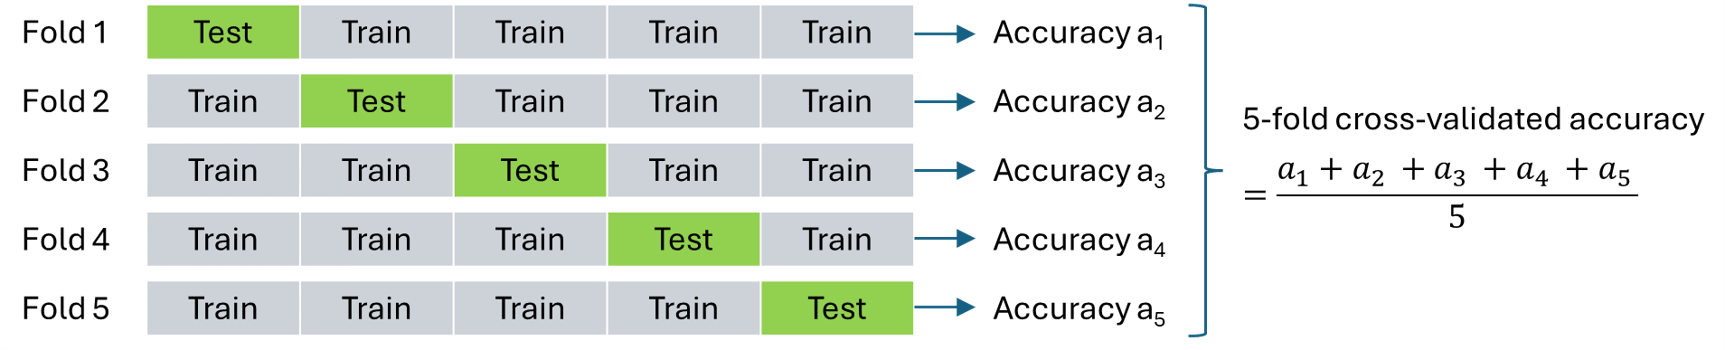

### Advantages of Cross Validate over Test/Split
    - ???




**The process for tuning k using cross validation:**

1. Pick a range of k values to try — e.g., k=1, 3, 5, 7, 9, 11...
2. For **each** k value, run the *full* 5-fold CV process (train 5 models, test 5 times, average the 5 scores).
3. You now have one **average CV accuracy per k value**.
4. Pick the k value with the highest average CV accuracy.
5. Retrain a final KNN model with that winning k, on the **entire** dataset.
6. Deploy that final model.

**Concretely:**

| KNN's k | Test=Fold1 (Train 2,3,4,5) | Test=Fold2 (Train 1,3,4,5) | Test=Fold3 (Train 1,2,4,5) | Test=Fold4 (Train 1,2,3,5) | Test=Fold5 (Train 1,2,3,4) | Average |
|---|---|---|---|---|---|---|
| k=1 | 0.80 | 0.75 | 0.82 | 0.78 | 0.79 | 0.788 |
| k=3 | 0.85 | 0.83 | 0.87 | 0.84 | 0.86 | 0.85 |
| k=5 | 0.88 | 0.86 | 0.89 | 0.87 | 0.88 | **0.876** ← best |
| k=7 | 0.86 | 0.85 | 0.87 | 0.86 | 0.85 | 0.858 |

Here you'd pick **k=5** (KNN's neighbor count — unrelated to the 5 in "5-fold," just a coincidence they're both 5 in this example) since it has the highest average accuracy across the folds.

**One nuance worth flagging:** if two k values have very close average scores (e.g., 0.876 vs 0.874), that difference might just be noise rather than a real signal that one is better. Some practitioners also look at the *standard deviation* across folds, not just the average — a k value with a high average but wildly inconsistent fold scores is less trustworthy than one with a slightly lower but more stable average.

This whole process — trying multiple hyperparameter values, each evaluated via k-fold CV — is called **grid search with cross-validation**, and it's exactly what `GridSearchCV` in scikit-learn automates for you.

## Cross Validation

The following is a plain Python implementation of the using cross-validation with kNN.

In [ ]:
import random
def make_folds(f, n):
    ''' 
    f: number of folds
    n: size of dataset
    return list of list of test indices for each fold
    [
        [1,2,3], # test indices for fold 1
        [4,5,6], # test indices for fold 2
        :
    ]
        training indices are implicitly those that are not in the test indices
    '''

    indices = list(range(n))
    random.shuffle(indices) 
    fold_indices = []
    start = 0
    for i in range(1,f+1): # get partial slices ending at :1/f,2/f..f/f * n
        end = int(i/f * n)
        fold_indices.append(indices[start:end])
        start = end
    return fold_indices

def cross_validate(k, fold_indices, features, labels):
    """Returns cross-validated accuracy using the given k, over pre-built folds."""
    accuracy_values = []
    for i in range(len(fold_indices)): # number of train/test cycles

        test_features = [features[j] for j in fold_indices[i]]
        test_labels = [labels[j] for j in fold_indices[i]]

        training_features = [features[j] for j in range(len(features))
                             if j not in fold_indices[i]] # not used in test fold
        training_labels = [labels[j] for j in range(len(labels))
                           if j not in fold_indices[i]]  # not used in test fold

        accuracy_values.append(calculate_accuracy(k, training_features, training_labels,
                                                  test_features, test_labels))
    return sum(accuracy_values) / len(accuracy_values)

### Generate the folds

In [ ]:
from ml_lib import plot_folds
k_cv = 5 #number of folds
fold_indices = make_folds(k_cv, len(features))  # built ONCE, reused for every k

plot_folds(fold_indices, features, labels)


### Evaluate best k based on cross fold validation
- for each k value, we use the same folds generated to get the average accuracy

In [ ]:
k_values = range(1, int((k_cv - 1) / k_cv * len(features))) # size of training features 
cv_values = []
print(f"For each k the the folds above are evaluated")
for k in k_values:
    cv_values.append(cross_validate(k, fold_indices, features, labels))

plt.xlabel('k')
plt.ylabel('Cross-validated accuracy')
plt.plot(k_values, cv_values)
plt.show()
print(f"Best k: {k_values[cv_values.index(max(cv_values))]}")

## Repeated k_folds (Not in syllabus)

In [ ]:
k_cv = 5 # number folds
k_values = range(2, int((k_cv - 1) / k_cv * len(features))) # range of k to evaluate

best_k = []
TRIALS=10
for _ in range(TRIALS): ## No of trials
    fold_indices = make_folds(k_cv, len(features))  # built ONCE, reused for every k
    cv_values = []
    for k in k_values:
        cv_values.append(cross_validate(k, fold_indices, features, labels))
    best_k.append(max(zip(cv_values, k_values))[1])

# print(best_k)
print(max(set(best_k), key=best_k.count))

In [ ]:
plt.figure(figsize=(10, 6))
plt.hist(best_k, bins=range(1, max(best_k) + 2), align='left', edgecolor='black')
plt.xlabel('k value')
plt.ylabel('Frequency')
plt.title('Frequency of Best k Values across Trials')
plt.xticks(range(1, max(best_k) + 1))
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

## Numpy implementation of Cross Validation

In [ ]:
import random, numpy as np
# return a list containig the k set of test indices of the test fold
def np_make_test_folds(f, n):
    ''' 
    f: number of folds
    n: size of dataset
    return list of list of test indices for each test fold
    e.g:
    data set = [0,1,2,3,4,5,6,7,8], folds = 3
    [
        [0,1,2], # test indices for fold 1
        [3,4,5], # test indices for fold 2
        [6,7,8], # test indices for fold 2
    ]

    '''

    indices = np.arange(n)
    random.shuffle(indices) 
    splits = np.linspace(0,len(indices),f+1,dtype=int) # generate f+1 intervals, step size is calcualted
    return  [ indices[splits[i]:splits[i+1]] for i in range(len(splits)-1)]


In [ ]:
## the folds are created first and then passed in to the cross validate function
import numpy as np

def np_cross_validate(k, test_folds, features, labels):
    """Returns cross-validated accuracy using the given k, over pre-built folds."""
    accuracy_values = []
    all_indices = np.arange(len(features))
    for test_indices in test_folds: # number of train/test cycles
        train_indices = all_indices[~np.isin(all_indices, test_indices)] #compliment of test_indices
        accuracy_values.append(
            np_calculate_accuracy(k, 
                               features[train_indices], 
                               labels[train_indices],
                               features[test_indices], 
                               labels[test_indices])
        )
    return sum(accuracy_values) / len(accuracy_values)

In [ ]:
# Generate folds and visualise

k_cv = 5 #number of folds
fold_indices = np_make_test_folds(k_cv, len(np_features))  # built ONCE, reused for every k
plot_folds(fold_indices, np_features, np_labels)



In [ ]:
# Evaluate best k from the folds generated

k_values = range(1, int((k_cv - 1) / k_cv * len(np_features))) # size of training features 
cv_values = []
for k in k_values: # every value of k uses the same folds for computing accuracy
    cv_values.append(np_cross_validate(k, fold_indices, np_features, np_labels))
plt.xlabel('k')
plt.ylabel('Cross-validated accuracy')
plt.plot(k_values, cv_values)
plt.show()
print(f"Best k: {k_values[cv_values.index(max(cv_values))]}")

In [ ]:
## repeated test folds

k_cv = 5 # number folds
k_values = range(2, int((k_cv - 1) / k_cv * len(np_features))) # range of k to evaluate

best_k = []
TRIALS=10 # Repeat the evaluations and get the k with highest frequency
for _ in range(TRIALS): ## No of trials
    fold_indices = np_make_test_folds(k_cv, len(np_features))  # built ONCE, reused for every k
    cv_values = []
    for k in k_values:
        cv_values.append(np_cross_validate(k, fold_indices, np_features, np_labels))
    best_k.append(max(zip(cv_values, k_values))[1]) # store the k value that has the highest accuracy

# print(best_k)
print(max(set(best_k), key=best_k.count))

In [ ]:
plt.figure(figsize=(10, 6))
plt.hist(best_k, bins=range(1, max(best_k) + 2), align='left', edgecolor='black')
plt.xlabel('k value')
plt.ylabel('Frequency')
plt.title('Frequency of Best k Values across Trials')
plt.xticks(range(1, max(best_k) + 1))
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()